# 00 — Démarrer : comprendre les données avant de modéliser

**Question :** peut-on anticiper le nombre d'actes criminels déclarés par PDQ et par semaine ?
Ce notebook n'entraîne **aucun modèle** : il vérifie ce que mesure la cible, ce qui manque,
et découpe les données dans le temps.

In [75]:
import sys
print(sys.executable)

/home/asd/ML510/Criminal-work/.venv/bin/python


In [76]:
import tomllib
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent                  # le notebook est dans notebooks/ → la racine est le dossier parent
with open(ROOT / "configs/crimes.toml", "rb") as f:
    cfg = tomllib.load(f)                 # cfg est maintenant un dictionnaire Python

SEED = cfg["experiment"]["seed"]
DATA_PATH = ROOT / cfg["data"]["path"]

raw = pd.read_csv(DATA_PATH, dtype={"PDQ": "string"})

print("Config :", cfg)
print("Lignes :", len(raw))
print("Première date :", raw["DATE"].min(), "| Dernière date :", raw["DATE"].max())
print()
print(raw.isna().sum())
raw.head()

Config : {'experiment': {'seed': 510}, 'data': {'path': 'Data/actes-criminels.csv'}, 'panel': {'lag_days': 14, 'active_since': '2025-01-01', 'min_acts': 100}, 'split': {'train_end': '2023-01-01', 'validation_end': '2024-01-01'}}
Lignes : 364699
Première date : 2015-01-01 | Dernière date : 2026-11-04

CATEGORIE        0
DATE             0
QUART            0
PDQ              8
X            60930
Y            60930
LONGITUDE    60930
LATITUDE     60930
dtype: int64


,CATEGORIE,DATE,QUART,PDQ,X,Y,LONGITUDE,LATITUDE
0,Vol de véhicule à moteur,2018-09-13,jour,30,294904.159001,5.047549e+06,-73.626778,45.567780
1,Vol de véhicule à moteur,2018-04-30,jour,30,294904.159001,5.047549e+06,-73.626778,45.567780
2,Vol de véhicule à moteur,2018-09-01,nuit,7,290274.565000,5.042150e+06,-73.685928,45.519122
3,Méfait,2017-07-21,jour,21,NaN,NaN,NaN,NaN
4,Méfait,2017-07-29,jour,12,NaN,NaN,NaN,NaN


## Nettoyage
On retire seulement les lignes sans DATE ou sans PDQ (impossibles à compter).
Les coordonnées GPS manquantes ne sont pas un problème : on compte par PDQ, pas par position.

In [77]:
df = raw.copy()                                             # on garde raw intact (brut = non modifié)
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")    # texte → vraie date

print("Dates illisibles :", df["DATE"].isna().sum())
print("Lignes sans PDQ :", df["PDQ"].isna().sum())

df = df.dropna(subset=["DATE", "PDQ"])                      # on retire SEULEMENT ce qui empêche le comptage
print("Lignes gardées :", len(df), "sur", len(raw))

Dates illisibles : 0
Lignes sans PDQ : 8
Lignes gardées : 364691 sur 364699


Prédire la semaine prochaine pour un poste fermé n’a aucun sens. On garde donc ceux qui ont au moins 100 actes depuis 2025

In [78]:
P = cfg["panel"]
recents = df.loc[df["DATE"] >= P["active_since"], "PDQ"].value_counts()   # nb d'actes par PDQ depuis 2025
pdqs = sorted(recents[recents >= P["min_acts"]].index, key=int)          # trié 1, 3, 4… (pas "1", "10", "12"…)

print(len(pdqs), "PDQ actifs :", pdqs)
print("Exclus :", sorted(set(df["PDQ"]) - set(pdqs), key=int))

29 PDQ actifs : ['1', '3', '4', '5', '7', '8', '9', '10', '12', '13', '15', '16', '20', '21', '23', '26', '27', '30', '31', '35', '38', '39', '42', '44', '45', '46', '48', '49', '50']
Exclus : ['11', '22', '24', '33', '55']


In [79]:
par_jour = df.groupby(df["DATE"].dt.date).size()
par_jour.tail(21)

DATE
2026-10-15    69
2026-10-16    83
2026-10-17    63
2026-10-18    72
2026-10-19    81
2026-10-20    82
2026-10-21    75
2026-10-22    83
2026-10-23    73
2026-10-24    74
2026-10-25    69
2026-10-26    65
2026-10-27    63
2026-10-28    75
2026-10-29    65
2026-10-30    49
2026-10-31    57
2026-11-01    57
2026-11-02    63
2026-11-03    54
2026-11-04    45
dtype: int64

## Latence de déclaration
Les derniers jours du fichier sont incomplets (délai de saisie), pas une baisse de la criminalité.
On ignore les 14 derniers jours et on ne garde que des semaines entières.

In [80]:
cutoff = df["DATE"].max() - pd.Timedelta(days=P["lag_days"])   # 2026-11-04 − 14 jours
semaine_du_cutoff = cutoff.to_period("W-SUN").start_time        # le lundi de la semaine qui contient le cutoff

# Si le cutoff tombe un dimanche, sa semaine est complète ; sinon on recule d'une semaine.
if cutoff.day_of_week == 6:
    derniere_semaine = semaine_du_cutoff
else:
    derniere_semaine = semaine_du_cutoff - pd.Timedelta(days=7)

print("Dernière date du fichier :", df["DATE"].max().date())
print("Cutoff (−14 jours)       :", cutoff.date(), cutoff.day_name())
print("Dernière semaine gardée  : du", derniere_semaine.date(), "au", (derniere_semaine + pd.Timedelta(days=6)).date())

Dernière date du fichier : 2026-11-04
Cutoff (−14 jours)       : 2026-10-21 Wednesday
Dernière semaine gardée  : du 2026-10-12 au 2026-10-18


## Panel PDQ × semaine
Une ligne = un PDQ actif pendant une semaine (lundi → dimanche), y = nombre d'actes déclarés.
Une semaine sans acte n'apparaît pas dans le CSV : on l'ajoute avec y = 0 (zéro explicite).

In [81]:
df["SEMAINE"] = df["DATE"].dt.to_period("W-SUN").dt.start_time   # le lundi de la semaine de l'acte

print("Premier jour du fichier :", df["DATE"].min().date(), df["DATE"].min().day_name())
print("Première semaine        :", df["SEMAINE"].min().date())
df[["DATE", "SEMAINE"]].head()




Premier jour du fichier : 2015-01-01 Thursday
Première semaine        : 2014-12-29


,DATE,SEMAINE
0,2018-09-13,2018-09-10
1,2018-04-30,2018-04-30
2,2018-09-01,2018-08-27
3,2017-07-21,2017-07-17
4,2017-07-29,2017-07-24


In [82]:
premiere_semaine = df["SEMAINE"].min()
if df["DATE"].min().day_of_week != 0:                  # le fichier ne commence pas un lundi…
    premiere_semaine = premiere_semaine + pd.Timedelta(days=7)   # …on saute cette semaine partielle

print("Panel : du", premiere_semaine.date(), "au", derniere_semaine.date())

Panel : du 2015-01-05 au 2026-10-12


In [83]:
garde = df["PDQ"].isin(pdqs) & df["SEMAINE"].between(premiere_semaine, derniere_semaine)
comptes = df[garde].groupby(["SEMAINE", "PDQ"]).size()

print("Actes gardés :", garde.sum())
print("Combinaisons (semaine, PDQ) qui ont AU MOINS un acte :", len(comptes))

Actes gardés : 343855
Combinaisons (semaine, PDQ) qui ont AU MOINS un acte : 17789


In [84]:
semaines = pd.date_range(premiere_semaine, derniere_semaine, freq="7D")       # TOUS les lundis
grille = pd.MultiIndex.from_product([semaines, pdqs], names=["SEMAINE", "PDQ"])  # chaque semaine × chaque PDQ

panel = comptes.reindex(grille, fill_value=0).rename("y").reset_index()

print("Semaines :", len(semaines), "| PDQ :", len(pdqs), "| Lignes attendues :", len(semaines) * len(pdqs))
print("Lignes du panel :", len(panel))
print("Zéros ajoutés   :", (panel["y"] == 0).sum())
print("Total des actes :", panel["y"].sum(), "(doit égaler les actes gardés)")
panel.head()

Semaines : 615 | PDQ : 29 | Lignes attendues : 17835
Lignes du panel : 17835
Zéros ajoutés   : 46
Total des actes : 343855 (doit égaler les actes gardés)


,SEMAINE,PDQ,y
0,2015-01-05,1,1
1,2015-01-05,3,7
2,2015-01-05,4,13
3,2015-01-05,5,14
4,2015-01-05,7,21


In [85]:
print(panel.loc[panel["y"] == 0, "PDQ"].value_counts())
panel["y"].describe()

PDQ
50    35
1      5
9      3
4      1
46     1
16     1
Name: count, dtype: int64


count    17835.000000
mean        19.279787
std         11.867167
min          0.000000
25%         11.000000
50%         17.000000
75%         25.000000
max        116.000000
Name: y, dtype: float64

## Découpage temporel
Train : semaines avant 2023 · Validation : 2023 · Test : 2024 et après (fermé jusqu'à la fin).
On n'explore QUE le train : regarder la validation ou le test pour trouver des idées les rendrait moins « frais ».

In [86]:
S = cfg["split"]
train_end = pd.Timestamp(S["train_end"])
validation_end = pd.Timestamp(S["validation_end"])

masks = {
    "train":      panel["SEMAINE"] < train_end,
    "validation": (panel["SEMAINE"] >= train_end) & (panel["SEMAINE"] < validation_end),
    "test":       panel["SEMAINE"] >= validation_end,
}

for nom, m in masks.items():
    sous = panel[m]
    print(f"{nom:<11} {len(sous):>6} lignes | {sous['SEMAINE'].nunique():>3} semaines | "
          f"du {sous['SEMAINE'].min().date()} au {sous['SEMAINE'].max().date()}")

# Contrôle : chaque ligne est dans UN SEUL ensemble
total = sum(m.sum() for m in masks.values())
print("Total :", total, "=", len(panel), "?", total == len(panel))

train        12093 lignes | 417 semaines | du 2015-01-05 au 2022-12-26
validation    1508 lignes |  52 semaines | du 2023-01-02 au 2023-12-25
test          4234 lignes | 146 semaines | du 2024-01-01 au 2026-10-12
Total : 17835 = 17835 ? True


In [87]:
for nom in ["train", "validation"]:
    y = panel.loc[masks[nom], "y"]
    print(f"{nom:<11} moyenne {y.mean():6.2f} | médiane {y.median():5.1f}")

train       moyenne  18.64 | médiane  17.0
validation  moyenne  22.25 | médiane  19.5


### Limite connue : fermeture du PDQ 22 (fin 2024)
Son territoire a été redistribué, surtout au PDQ 21 (+23 % d'actes sur 12 mois alors que la plupart des PDQ baissent).
Ce n'est pas une hausse de la criminalité mais un changement de ce que mesure « PDQ 21 ».
Cette rupture tombe dans la période de test : le modèle ne l'a jamais vue. À vérifier : erreur par PDQ.

## Analyse exploratoire (train seulement : 2015–2022)
Trois questions : où, quand dans l'année, et comment le volume évolue-t-il d'une année à l'autre ?

In [88]:
import matplotlib.pyplot as plt

train = panel[masks["train"]].copy()       # on n'explore QUE le train
print("Lignes du train :", len(train))

Lignes du train : 12093


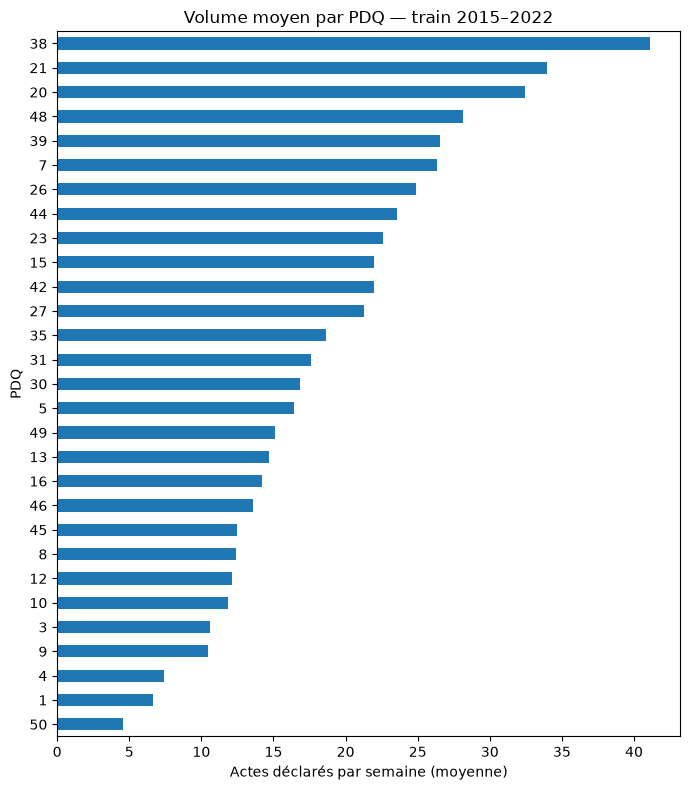

Les 5 plus chargés : {'39': 26.5, '48': 28.1, '20': 32.5, '21': 34.0, '38': 41.1}
Les 4 moins chargés : {'50': 4.6, '1': 6.7, '4': 7.4, '9': 10.4}


In [89]:
par_pdq = train.groupby("PDQ")["y"].mean().sort_values()

ax = par_pdq.plot(kind="barh", figsize=(7, 8))
ax.set_xlabel("Actes déclarés par semaine (moyenne)")
ax.set_ylabel("PDQ")
ax.set_title("Volume moyen par PDQ — train 2015–2022")
plt.tight_layout()
plt.show()

print("Les 5 plus chargés :", par_pdq.tail(5).round(1).to_dict())
print("Les 4 moins chargés :", par_pdq.head(4).round(1).to_dict())

**Constat — Où.** Le volume varie d'un facteur ~9 entre PDQ (38 : ~41/semaine ; 50 : ~5/semaine).
Le PDQ est donc l'information la plus importante pour le modèle (rôle de l'heure chez les vélos).
Une même erreur de 5 actes est faible pour le PDQ 38, mais énorme pour le PDQ 50 : il faudra regarder l'erreur par PDQ.

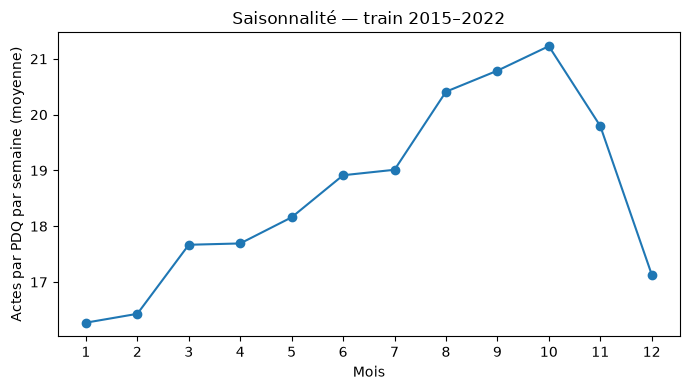

{1: 16.3, 2: 16.4, 3: 17.7, 4: 17.7, 5: 18.2, 6: 18.9, 7: 19.0, 8: 20.4, 9: 20.8, 10: 21.2, 11: 19.8, 12: 17.1}


In [90]:
par_mois = train.groupby(train["SEMAINE"].dt.month)["y"].mean()

ax = par_mois.plot(marker="o", figsize=(7, 4))
ax.set_xticks(range(1, 13))
ax.set_xlabel("Mois")
ax.set_ylabel("Actes par PDQ par semaine (moyenne)")
ax.set_title("Saisonnalité — train 2015–2022")
plt.tight_layout()
plt.show()

print(par_mois.round(1).to_dict())

**Constat — Quand.** Saison marquée : creux en janvier–février (~16), pic en septembre–octobre (~21), soit ~30 % d'écart.
Le mois est une information utile pour le modèle.

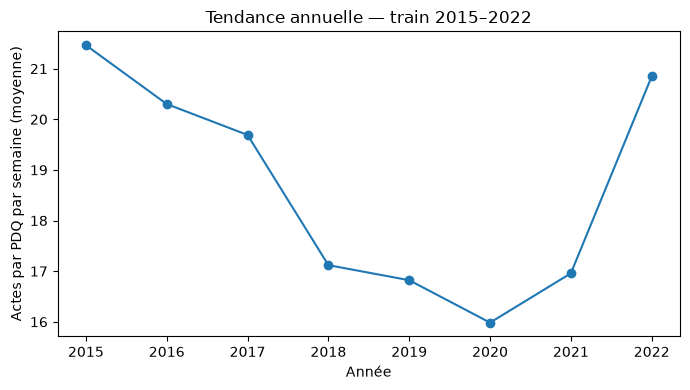

{2015: 21.46, 2016: 20.3, 2017: 19.69, 2018: 17.12, 2019: 16.82, 2020: 15.98, 2021: 16.96, 2022: 20.85}


In [91]:
par_annee = train.groupby(train["SEMAINE"].dt.year)["y"].mean()

ax = par_annee.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("Année")
ax.set_ylabel("Actes par PDQ par semaine (moyenne)")
ax.set_title("Tendance annuelle — train 2015–2022")
plt.tight_layout()
plt.show()

print(par_annee.round(2).to_dict())

**Constat — Tendance.** Baisse de 2015 à 2020 (creux, année de pandémie), puis remontée nette en 2021–2022.
La tendance n'est pas une ligne droite : un modèle qui prolonge une tendance linéaire apprise sur 2015–2022
prédirait une baisse, alors que 2023 continue de monter. C'est pourquoi la validation (22,3) est plus haute que la moyenne du train (18,6).
Conséquence pour le notebook 01 : comparer à une référence simple, et se méfier d'une tendance « en ligne droite ».

## Contrat de prédiction (v1)
**Pour chaque PDQ actif, chaque dimanche soir, estimer le nombre d'actes criminels déclarés
pour la semaine suivante (lundi → dimanche), à partir d'informations connues à l'avance
(PDQ, mois, temps écoulé), afin que l'analyste puisse préparer le bilan hebdomadaire
et repérer les PDQ au-dessus de leur normale.**

| Élément | Valeur |
|---|---|
| Unité | 1 PDQ actif × 1 semaine (lundi → dimanche) |
| Cible `y` | actes **déclarés et enregistrés** (pas « la criminalité ») |
| Moment | avant le début de la semaine |
| Entrées | calendrier seulement : PDQ, mois, temps écoulé |
| Action | aide au bilan et au repérage — pas une décision automatique |
| Hors contrat | actes non déclarés ; PDQ fermés ; les 14 derniers jours (non consolidés) |